# Multi-Class Sentiment Analysis: NN vs RNN vs LSTM vs GRU with Automated Hyperparameter Tuning

**Dataset:** [`Sp1786/multiclass-sentiment-analysis-dataset`](https://huggingface.co/datasets/Sp1786/multiclass-sentiment-analysis-dataset) (about 41.6k rows)  
**Classes:** `0 = Negative`, `1 = Neutral`, `2 = Positive`  
**Framework:** TensorFlow / Keras + Keras Tuner  
**Platform:** Google Colab (GPU recommended: *Runtime → Change runtime type → T4 GPU*)

### Project objective
Build, tune and compare four neural architectures on the same data:

| Model | Architecture |
|---|---|
| **NN** | `Embedding → GlobalAveragePooling1D → Dense` (order-agnostic baseline) |
| **RNN** | `Embedding → Bidirectional(SimpleRNN)` |
| **LSTM** | `Embedding → Bidirectional(LSTM)` |
| **GRU** | `Embedding → Bidirectional(GRU)` |

Each model's hyperparameters are tuned **automatically** by `keras_tuner.RandomSearch` over predefined ranges. The best configuration of each model is retrained, evaluated once on the unseen test split, and the overall best model and its parameters are reported.

**Workflow:** load data → clean → explore → tokenize → define models → tune → retrain best configs → compare → diagnose → predict → save.

## 1. Install and import libraries

In [2]:
!pip -q install datasets keras-tuner

In [14]:
import os, re, gc, json, time, random, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras_tuner as kt
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

print("TensorFlow :", tf.__version__)
print("Keras Tuner:", kt.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.21.0
Keras Tuner: 1.4.8
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Experiment configuration
All the knobs of the experiment are in one place. Increase `MAX_TRIALS` for a more exhaustive search (slower), or lower it for a quick run.

The **search space** below is the set of predefined ranges the tuner explores for every architecture.

In [15]:
LABELS      = ["Negative", "Neutral", "Positive"]   # 0, 1, 2
NUM_CLASSES = len(LABELS)
ARCHS       = ["NN", "RNN", "LSTM", "GRU"]

# ---- Text pipeline ----
VOCAB_SIZE  = 20000      # max vocabulary size (fit on training split only)
MAX_LEN_CAP = 80         # upper bound for the sequence length

# ---- Tuning / training budget ----
MAX_TRIALS   = 5         # random-search trials PER architecture
TUNE_EPOCHS  = 6         # max epochs per trial (early stopping applies)
FINAL_EPOCHS = 15        # max epochs when retraining the best configuration
PATIENCE     = 2         # early-stopping patience while tuning

# ---- Predefined hyperparameter ranges ----
HP_SPACE = {
    "embed_dim":     [64, 128, 200],
    "units":         dict(min_value=64, max_value=160, step=32),   # 64, 96, 128, 160
    "dropout":       dict(min_value=0.2, max_value=0.5, step=0.1), # 0.2 ... 0.5
    "learning_rate": [1e-3, 5e-4, 2e-4],
    "batch_size":    [64, 128],
}
HP_NAMES = list(HP_SPACE.keys())

n_units   = len(range(HP_SPACE["units"]["min_value"], HP_SPACE["units"]["max_value"] + 1, HP_SPACE["units"]["step"]))
n_dropout = 4
total     = len(HP_SPACE["embed_dim"]) * n_units * n_dropout * len(HP_SPACE["learning_rate"]) * len(HP_SPACE["batch_size"])
print(f"Possible combinations per architecture: {total}")
print(f"Trials per architecture: {MAX_TRIALS}  |  total tuning trials: {MAX_TRIALS * len(ARCHS)}")

Possible combinations per architecture: 288
Trials per architecture: 5  |  total tuning trials: 20


## 3. Load the dataset
The dataset ships with predefined **train / validation / test** splits on Hugging Face, so no custom splitting is needed. If the `datasets` library cannot reach the hub, the notebook falls back to downloading the CSV files directly.

In [16]:
def load_splits():
    try:
        from datasets import load_dataset
        ds = load_dataset("Sp1786/multiclass-sentiment-analysis-dataset")
        return (ds["train"].to_pandas(), ds["validation"].to_pandas(), ds["test"].to_pandas())
    except Exception as e:
        print("`datasets` loader failed, falling back to CSV download:", repr(e)[:120])
        base = "https://huggingface.co/datasets/Sp1786/multiclass-sentiment-analysis-dataset/resolve/main"
        return tuple(pd.read_csv(f"{base}/{name}.csv") for name in ["train_df", "val_df", "test_df"])

train_raw, val_raw, test_raw = load_splits()
print("Raw split sizes (train / val / test):", train_raw.shape, val_raw.shape, test_raw.shape)
print("Columns:", train_raw.columns.tolist())
train_raw.head()

README.md:   0%|          | 0.00/1.72k [00:00<?, ?B/s]

train_df.csv:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

val_df.csv:   0%|          | 0.00/601k [00:00<?, ?B/s]

test_df.csv:   0%|          | 0.00/586k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/31232 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5205 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5206 [00:00<?, ? examples/s]

Raw split sizes (train / val / test): (31232, 4) (5205, 4) (5206, 4)
Columns: ['id', 'text', 'label', 'sentiment']


,id,text,label,sentiment
0,9536,"Cooking microwave pizzas, yummy",2,positive
1,6135,Any plans of allowing sub tasks to show up in ...,1,neutral
2,17697,"I love the humor, I just reworded it. Like sa...",2,positive
3,14182,naw idk what ur talkin about,1,neutral
4,17840,That sucks to hear. I hate days like that,0,negative


## 4. Clean the data and verify the labels
* Keep only `text` and `label`.
* Drop rows with missing / empty text or labels outside `{0, 1, 2}`.
* Convert labels to integers.

In [17]:
def clean_split(df):
    df = df[["text", "label"]].dropna().copy()
    df["text"] = df["text"].astype(str).str.strip()
    df["label"] = pd.to_numeric(df["label"], errors="coerce")
    df = df.dropna()
    df = df[df["text"].str.len() > 0]
    df["label"] = df["label"].astype(int)
    return df[df["label"].isin(range(NUM_CLASSES))].reset_index(drop=True)

train_df, val_df, test_df = map(clean_split, [train_raw, val_raw, test_raw])
print("Clean split sizes (train / val / test):", len(train_df), len(val_df), len(test_df))
print("Label mapping: 0=Negative, 1=Neutral, 2=Positive")

Clean split sizes (train / val / test): 31232 5205 5205
Label mapping: 0=Negative, 1=Neutral, 2=Positive


## 5. Exploratory data analysis

,sentiment,count,percentage
0,Negative,9105,29.15
1,Neutral,11649,37.30
2,Positive,10478,33.55


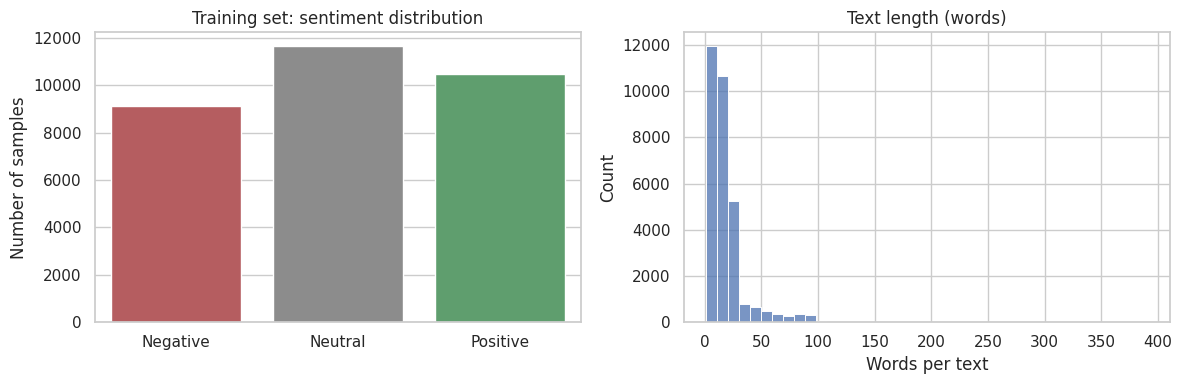

count    31232.0
mean        18.0
std         17.8
min          1.0
25%          8.0
50%         13.0
75%         21.0
max        391.0

Sample texts per class:
  [Negative] That sucks to hear. I hate days like that
  [Neutral] Any plans of allowing sub tasks to show up in the widget?
  [Positive] Cooking microwave pizzas, yummy


In [18]:
counts = train_df["label"].value_counts().reindex(range(NUM_CLASSES), fill_value=0)
dist = pd.DataFrame({"sentiment": LABELS, "count": counts.values,
                     "percentage": (counts.values / counts.sum() * 100).round(2)})
display(dist)

train_df["n_words"] = train_df["text"].str.split().str.len()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=LABELS, y=counts.values, ax=ax[0], palette=["#C44E52", "#8C8C8C", "#55A868"])
ax[0].set_title("Training set: sentiment distribution")
ax[0].set_ylabel("Number of samples")
sns.histplot(train_df["n_words"], bins=40, ax=ax[1], color="#4C72B0")
ax[1].set_title("Text length (words)")
ax[1].set_xlabel("Words per text")
plt.tight_layout(); plt.show()

print(train_df["n_words"].describe().round(1).to_string())
print("\nSample texts per class:")
for i, name in enumerate(LABELS):
    print(f"  [{name}]", train_df.loc[train_df.label == i, "text"].iloc[0][:110])

## 6. Text normalization and tokenization
Normalization is deliberately light, because punctuation (`!`, `?`), negations (`not`, `n't`) and casing carry sentiment:

* lower-case, replace URLs with `url` and `@mentions` with `user`;
* put spaces around punctuation so `great!` becomes the tokens `great` and `!`.

`TextVectorization` is **fitted on the training split only** (no leakage) and unseen words map to the out-of-vocabulary token. Sequences are padded to a fixed length chosen from the data (98th percentile, capped by `MAX_LEN_CAP`).

In [19]:
def normalize_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " url ", text)
    text = re.sub(r"@\w+", " user ", text)
    text = re.sub(r"([!?.,;:*()\"])", r" \1 ", text)
    return re.sub(r"\s+", " ", text).strip()

for frame in (train_df, val_df, test_df):
    frame["clean_text"] = frame["text"].apply(normalize_text)

token_lengths = train_df["clean_text"].str.split().str.len()
MAX_LEN = int(min(np.percentile(token_lengths, 98), MAX_LEN_CAP))
print("MAX_LEN (98th percentile, capped):", MAX_LEN)

vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=VOCAB_SIZE, output_mode="int",
    output_sequence_length=MAX_LEN, standardize=None, split="whitespace")
vectorizer.adapt(tf.data.Dataset.from_tensor_slices(train_df["clean_text"].values).batch(1024))

def encode(frame):
    return vectorizer(frame["clean_text"].values).numpy()

X_train, X_val, X_test = encode(train_df), encode(val_df), encode(test_df)
y_train, y_val, y_test = (f["label"].to_numpy() for f in (train_df, val_df, test_df))
ACTUAL_VOCAB = len(vectorizer.get_vocabulary())

print("Vocabulary size:", ACTUAL_VOCAB)
print("Tensor shapes  :", X_train.shape, X_val.shape, X_test.shape)
print("Example        :", train_df["clean_text"].iloc[0][:80], "->", X_train[0][:12], "...")

MAX_LEN (98th percentile, capped): 80
Vocabulary size: 20000
Tensor shapes  : (31232, 80) (5205, 80) (5205, 80)
Example        : cooking microwave pizzas , yummy -> [ 2766 10313  6137     7  1293     0     0     0     0     0     0     0] ...


## 7. Handle class imbalance
Balanced class weights make the loss pay proportionally more attention to the under-represented classes.

In [20]:
classes = np.unique(y_train)
cw = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = {int(c): float(w) for c, w in zip(classes, cw)}
print("Class weights:", {LABELS[k]: round(v, 3) for k, v in class_weights.items()})

Class weights: {'Negative': 1.143, 'Neutral': 0.894, 'Positive': 0.994}


## 8. Model architectures
One function, `make_model`, builds all four architectures so they differ **only** in the sequence-processing block. The same function is used by the tuner and for the final retraining.

* **NN** averages the word embeddings (ignores word order) and adds a Dense layer.
* **RNN / LSTM / GRU** read the sequence forwards *and* backwards (`Bidirectional`) so each word sees both left and right context.
* `mask_zero=True` makes every model ignore the padding tokens.
* Every model ends with `Dropout → Dense(3, softmax)`.

In [21]:
def make_model(arch, embed_dim, units, dropout, learning_rate):
    L = tf.keras.layers
    model = tf.keras.Sequential(name=arch)
    model.add(L.Input(shape=(MAX_LEN,), dtype="int32"))
    model.add(L.Embedding(ACTUAL_VOCAB, embed_dim, mask_zero=True))

    if arch == "NN":
        model.add(L.GlobalAveragePooling1D())
        model.add(L.Dense(units, activation="relu"))
    elif arch == "RNN":
        model.add(L.Bidirectional(L.SimpleRNN(units)))
    elif arch == "LSTM":
        model.add(L.Bidirectional(L.LSTM(units)))
    elif arch == "GRU":
        model.add(L.Bidirectional(L.GRU(units)))
    else:
        raise ValueError(f"Unknown architecture: {arch}")

    model.add(L.Dropout(dropout))
    model.add(L.Dense(NUM_CLASSES, activation="softmax"))
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

## 9. Automated hyperparameter tuning (Keras Tuner, random search)
For every architecture, `RandomSearch` samples `MAX_TRIALS` configurations from `HP_SPACE`, trains each with early stopping, and keeps the one with the highest **validation accuracy**. The **batch size** is tuned as well, through the `fit` override of the `HyperModel`.

In [22]:
import keras_tuner as kt
class SentimentHyperModel(kt.HyperModel):
    def __init__(self, arch):
        super().__init__()
        self.arch = arch

    def build(self, hp):
        params = dict(
            embed_dim=hp.Choice("embed_dim", HP_SPACE["embed_dim"]),
            units=hp.Int("units", **HP_SPACE["units"]),
            dropout=hp.Float("dropout", **HP_SPACE["dropout"]),
            learning_rate=hp.Choice("learning_rate", HP_SPACE["learning_rate"]),
        )
        hp.Choice("batch_size", HP_SPACE["batch_size"])   # registered so it is part of the search space
        return make_model(self.arch, **params)

    def fit(self, hp, model, *args, **kwargs):
        return model.fit(*args, batch_size=hp.Choice("batch_size", HP_SPACE["batch_size"]), **kwargs)

def tidy(values):
    """Round floats so e.g. 0.30000000000000004 is shown as 0.3."""
    return {k: (round(v, 4) if isinstance(v, float) else v) for k, v in values.items()}


tuners, trial_frames, best_hps = {}, [], {}

TUNER_DIR = "tuner_runs"

for arch in ARCHS:

    print(f"\n{'=' * 18} TUNING {arch} {'=' * 18}")

    tf.keras.backend.clear_session()
    gc.collect()

    tuner = kt.RandomSearch(
        SentimentHyperModel(arch),
        objective="val_accuracy",
        max_trials=MAX_TRIALS,
        executions_per_trial=1,
        seed=SEED,
        directory=TUNER_DIR,
        project_name=f"{arch}_tuning",
        overwrite=True,
    )

    t0 = time.time()

    tuner.search(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=TUNE_EPOCHS,
        class_weight=class_weights,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=PATIENCE,
                restore_best_weights=True
            )
        ],
        verbose=1,
    )

    elapsed = time.time() - t0

    best_hps[arch] = tuner.get_best_hyperparameters(1)[0]
    tuners[arch] = tuner

    for t in tuner.oracle.get_best_trials(MAX_TRIALS):
        trial_frames.append({
            "architecture": arch,
            "trial_id": t.trial_id,
            "val_accuracy": t.score,
            **tidy(t.hyperparameters.values)
        })

    best_score = max(
        r["val_accuracy"]
        for r in trial_frames
        if r["architecture"] == arch
    )

    print(
        f"\n{arch}: Best validation accuracy = {best_score:.4f}"
    )

    print(f"Tuning time = {elapsed / 60:.2f} minutes")

    print(
        "Best hyperparameters:",
        tidy({
            k: best_hps[arch].values[k]
            for k in HP_NAMES
        })
    )

tuning_df = pd.DataFrame(trial_frames)

print("\nAll architecture tuning completed!")

Trial 5 Complete [00h 00m 25s]
val_accuracy: 0.6774255633354187

Best val_accuracy So Far: 0.6829971075057983
Total elapsed time: 00h 01m 42s

GRU: Best validation accuracy = 0.6830
Tuning time = 1.70 minutes
Best hyperparameters: {'embed_dim': 64, 'units': 128, 'dropout': 0.2, 'learning_rate': 0.001, 'batch_size': 64}

All architecture tuning completed!


## 10. Tuning results

,architecture,val_accuracy,embed_dim,units,dropout,learning_rate,batch_size
0,GRU,0.6830,64,128,0.2,0.0010,64
1,GRU,0.6788,200,128,0.4,0.0010,128
2,GRU,0.6774,200,96,0.3,0.0005,64
3,GRU,0.6740,128,64,0.3,0.0010,128
4,GRU,0.6730,128,128,0.2,0.0005,64
5,LSTM,0.6776,128,128,0.2,0.0005,64
6,LSTM,0.6774,200,96,0.3,0.0005,64
7,LSTM,0.6772,128,64,0.3,0.0010,128
8,LSTM,0.6772,64,128,0.2,0.0010,64
9,LSTM,0.6732,200,128,0.4,0.0010,128


Best configuration per architecture (by validation accuracy):


,architecture,val_accuracy,embed_dim,units,dropout,learning_rate,batch_size
0,GRU,0.6830,64,128,0.2,0.0010,64
1,LSTM,0.6776,128,128,0.2,0.0005,64
2,NN,0.6669,128,128,0.2,0.0005,64
3,RNN,0.6574,128,64,0.3,0.0010,128


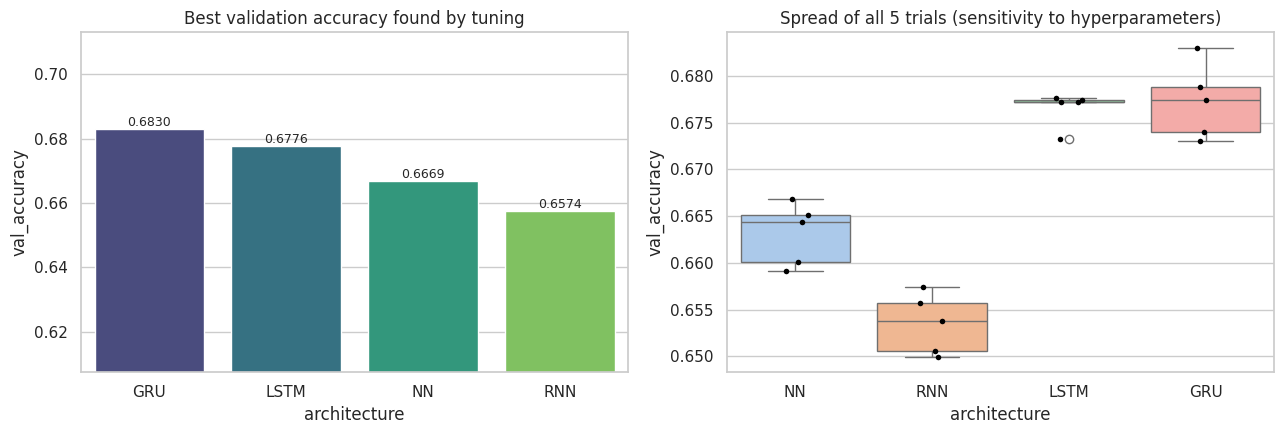

In [23]:
display_cols = ["architecture", "val_accuracy"] + HP_NAMES
all_trials = tuning_df.sort_values(["architecture", "val_accuracy"], ascending=[True, False])
display(all_trials[display_cols].round(4).reset_index(drop=True))

best_val_df = (tuning_df.sort_values("val_accuracy", ascending=False)
               .groupby("architecture", as_index=False).first()
               .sort_values("val_accuracy", ascending=False))
print("Best configuration per architecture (by validation accuracy):")
display(best_val_df[display_cols].round(4).reset_index(drop=True))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=best_val_df, x="architecture", y="val_accuracy", ax=ax[0], palette="viridis")
ax[0].set_ylim(best_val_df["val_accuracy"].min() - 0.05, best_val_df["val_accuracy"].max() + 0.03)
ax[0].set_title("Best validation accuracy found by tuning")
for p in ax[0].patches:
    ax[0].annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom", fontsize=9)
sns.boxplot(data=tuning_df, x="architecture", y="val_accuracy", order=ARCHS, ax=ax[1], palette="pastel")
sns.stripplot(data=tuning_df, x="architecture", y="val_accuracy", order=ARCHS, ax=ax[1], color="black", size=4)
ax[1].set_title(f"Spread of all {MAX_TRIALS} trials (sensitivity to hyperparameters)")
plt.tight_layout(); plt.show()

## 11. Retrain the best configuration of each architecture
The winning hyperparameters of every model are used to train a fresh model for up to `FINAL_EPOCHS` epochs with early stopping and learning-rate reduction. The **test set is touched only now**, once per model.

In [24]:
final_models, histories, test_preds, test_probs, rows = {}, {}, {}, {}, []

for arch in ARCHS:
    hp = best_hps[arch]
    params = tidy({k: hp.values[k] for k in HP_NAMES})
    tf.keras.backend.clear_session(); gc.collect()
    tf.keras.utils.set_random_seed(SEED)

    model = make_model(arch, params["embed_dim"], params["units"],
                       params["dropout"], params["learning_rate"])
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
    ]
    print(f"\nTraining final {arch} with {params}")
    t0 = time.time()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=FINAL_EPOCHS, batch_size=params["batch_size"],
                        class_weight=class_weights, callbacks=callbacks, verbose=2)
    seconds = time.time() - t0

    probs = model.predict(X_test, verbose=0)
    pred = probs.argmax(axis=1)
    val_pred = model.predict(X_val, verbose=0).argmax(axis=1)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)

    final_models[arch], histories[arch] = model, history
    test_preds[arch], test_probs[arch] = pred, probs
    rows.append({
        "architecture": arch,
        "val_accuracy": accuracy_score(y_val, val_pred),
        "test_accuracy": accuracy_score(y_test, pred),
        "macro_precision": prec, "macro_recall": rec, "test_macro_f1": f1,
        "epochs_run": len(history.history["loss"]),
        "training_seconds": seconds, "parameters": model.count_params(),
        **params,
    })


Training final NN with {'embed_dim': 128, 'units': 128, 'dropout': 0.2, 'learning_rate': 0.0005, 'batch_size': 64}
Epoch 1/15
488/488 - 5s - 11ms/step - accuracy: 0.5835 - loss: 0.8851 - val_accuracy: 0.6565 - val_loss: 0.7628 - learning_rate: 5.0000e-04
Epoch 2/15
488/488 - 2s - 4ms/step - accuracy: 0.7232 - loss: 0.6565 - val_accuracy: 0.6665 - val_loss: 0.7517 - learning_rate: 5.0000e-04
Epoch 3/15
488/488 - 2s - 4ms/step - accuracy: 0.7777 - loss: 0.5557 - val_accuracy: 0.6609 - val_loss: 0.7956 - learning_rate: 5.0000e-04
Epoch 4/15
488/488 - 2s - 4ms/step - accuracy: 0.8141 - loss: 0.4840 - val_accuracy: 0.6473 - val_loss: 0.8615 - learning_rate: 5.0000e-04
Epoch 5/15
488/488 - 3s - 5ms/step - accuracy: 0.8525 - loss: 0.4056 - val_accuracy: 0.6398 - val_loss: 0.9052 - learning_rate: 2.5000e-04
Epoch 6/15
488/488 - 2s - 4ms/step - accuracy: 0.8646 - loss: 0.3761 - val_accuracy: 0.6325 - val_loss: 0.9532 - learning_rate: 2.5000e-04

Training final RNN with {'embed_dim': 128, 'unit

## 12. Final comparison and best model

In [25]:
comparison = (pd.DataFrame(rows)
              .sort_values(["test_macro_f1", "test_accuracy"], ascending=False)
              .reset_index(drop=True))
comparison.index = comparison.index + 1
comparison.index.name = "rank"
display(comparison.round(4))

winner = comparison.iloc[0]
best_arch = winner["architecture"]
print("=" * 60)
print("BEST PERFORMING MODEL:", best_arch)
print(f"  Test accuracy  : {winner['test_accuracy']:.4f}")
print(f"  Macro precision: {winner['macro_precision']:.4f}")
print(f"  Macro recall   : {winner['macro_recall']:.4f}")
print(f"  Test macro-F1  : {winner['test_macro_f1']:.4f}")
print("  Best hyperparameters:")
for p in HP_NAMES:
    print(f"     {p:<14}: {winner[p]}")
print("=" * 60)

,architecture,val_accuracy,test_accuracy,macro_precision,macro_recall,test_macro_f1,epochs_run,training_seconds,parameters,embed_dim,units,dropout,learning_rate,batch_size
rank,,,,,,,,,,,,,,
1,GRU,0.6849,0.6886,0.6938,0.6904,0.6919,5,33.5885,1429763,64,128,0.2,0.0010,64
2,LSTM,0.6734,0.6740,0.6804,0.6766,0.6780,5,40.0902,2823939,128,128,0.2,0.0005,64
3,NN,0.6665,0.6745,0.6783,0.6773,0.6777,6,15.7681,2576899,128,128,0.2,0.0005,64
4,RNN,0.6496,0.6586,0.6666,0.6624,0.6633,5,25.4316,2585091,128,64,0.3,0.0010,128


BEST PERFORMING MODEL: GRU
  Test accuracy  : 0.6886
  Macro precision: 0.6938
  Macro recall   : 0.6904
  Test macro-F1  : 0.6919
  Best hyperparameters:
     embed_dim     : 64
     units         : 128
     dropout       : 0.2
     learning_rate : 0.001
     batch_size    : 64


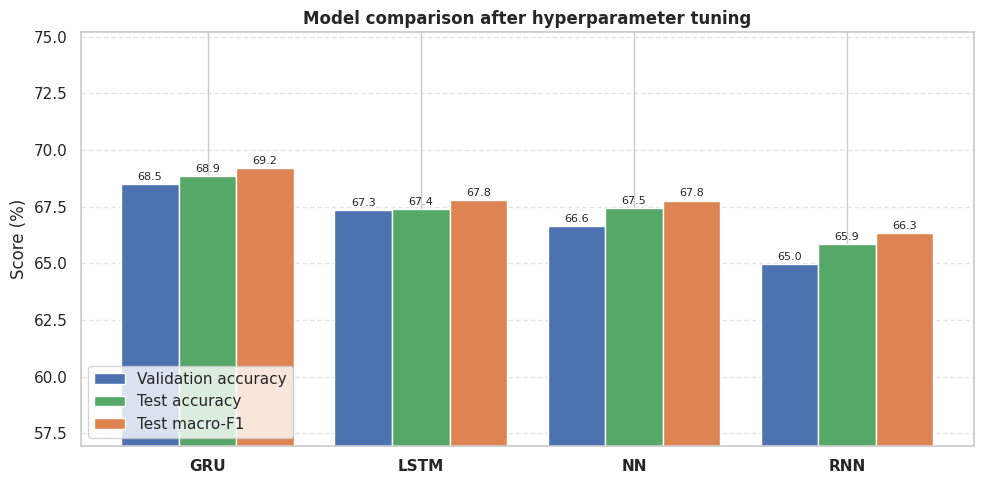

In [26]:
order = comparison["architecture"].tolist()
x = np.arange(len(order)); w = 0.27
metrics = [("val_accuracy", "Validation accuracy", "#4C72B0"),
           ("test_accuracy", "Test accuracy", "#55A868"),
           ("test_macro_f1", "Test macro-F1", "#DD8452")]

fig, ax = plt.subplots(figsize=(10, 5))
for i, (col, label, color) in enumerate(metrics):
    vals = comparison.set_index("architecture").loc[order, col].values * 100
    bars = ax.bar(x + (i - 1) * w, vals, w, label=label, color=color)
    for b in bars:
        ax.annotate(f"{b.get_height():.1f}", (b.get_x() + b.get_width() / 2, b.get_height()),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
lo = comparison[["val_accuracy", "test_accuracy", "test_macro_f1"]].min().min() * 100
ax.set_ylim(max(0, lo - 8), min(100, comparison[["val_accuracy", "test_accuracy", "test_macro_f1"]].max().max() * 100 + 6))
ax.set_xticks(x); ax.set_xticklabels(order, fontweight="bold")
ax.set_ylabel("Score (%)")
ax.set_title("Model comparison after hyperparameter tuning", fontweight="bold")
ax.legend(loc="lower left"); ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout(); plt.savefig("model_comparison_chart.png", dpi=200); plt.show()

## 13. Classification report and confusion matrices

=== Classification report: best model (GRU) ===
              precision    recall  f1-score   support

    Negative     0.6915    0.6915    0.6915      1546
     Neutral     0.6172    0.6428    0.6298      1929
    Positive     0.7727    0.7370    0.7544      1730

    accuracy                         0.6886      5205
   macro avg     0.6938    0.6904    0.6919      5205
weighted avg     0.6910    0.6886    0.6895      5205



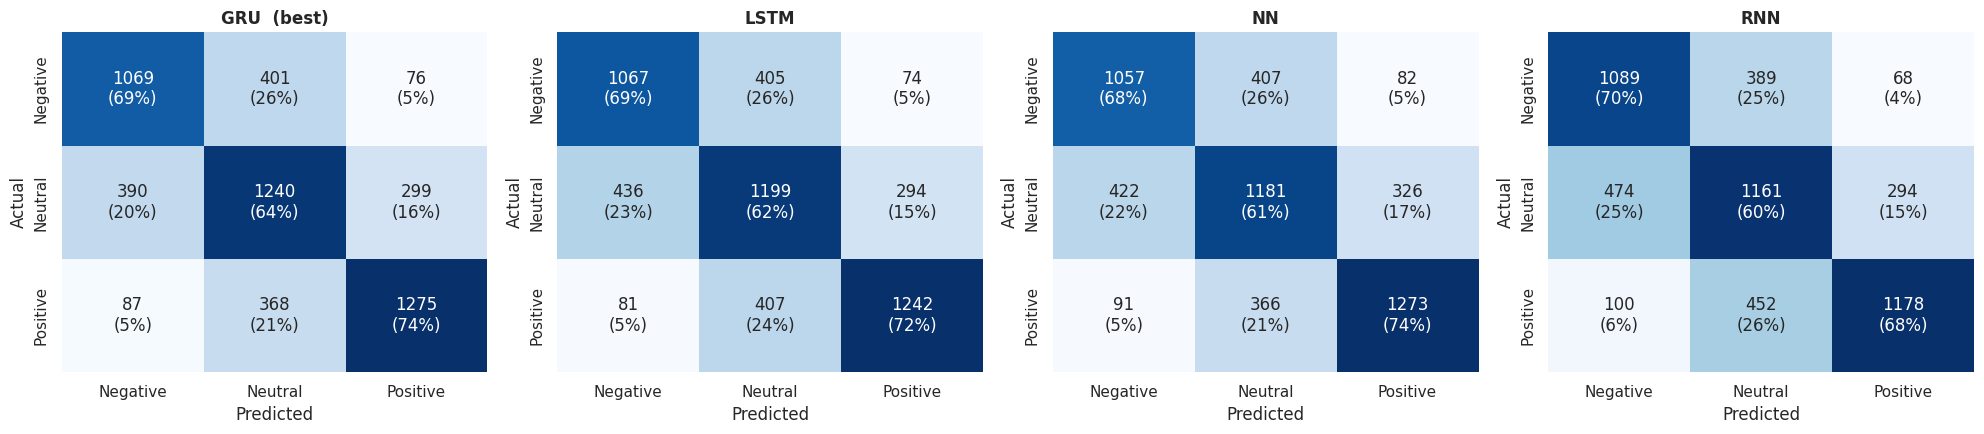

In [27]:
print(f"=== Classification report: best model ({best_arch}) ===")
print(classification_report(y_test, test_preds[best_arch], labels=[0, 1, 2],
                            target_names=LABELS, digits=4, zero_division=0))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, arch in zip(axes, order):
    cm = confusion_matrix(y_test, test_preds[arch], labels=[0, 1, 2])
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    sns.heatmap(cm, annot=np.array([[f"{c}\n({p:.0f}%)" for c, p in zip(r1, r2)]
                                    for r1, r2 in zip(cm, cm_pct)]),
                fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=LABELS, yticklabels=LABELS)
    ax.set_title(f"{arch}" + ("  (best)" if arch == best_arch else ""), fontweight="bold")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.savefig("confusion_matrices.png", dpi=200); plt.show()

In [28]:
per_class = []
for arch in order:
    p, r, f, _ = precision_recall_fscore_support(y_test, test_preds[arch], labels=[0, 1, 2], zero_division=0)
    for i, name in enumerate(LABELS):
        per_class.append({"architecture": arch, "class": name, "precision": p[i], "recall": r[i], "f1": f[i]})
per_class_df = pd.DataFrame(per_class)
display(per_class_df.pivot(index="architecture", columns="class", values="f1").loc[order].round(4)
        .rename_axis(columns="F1 by class"))

F1 by class,Negative,Neutral,Positive
architecture,,,
GRU,0.6915,0.6298,0.7544
LSTM,0.6818,0.6086,0.7437
NN,0.6784,0.6083,0.7464
RNN,0.6787,0.5907,0.7205


## 14. Learning curves

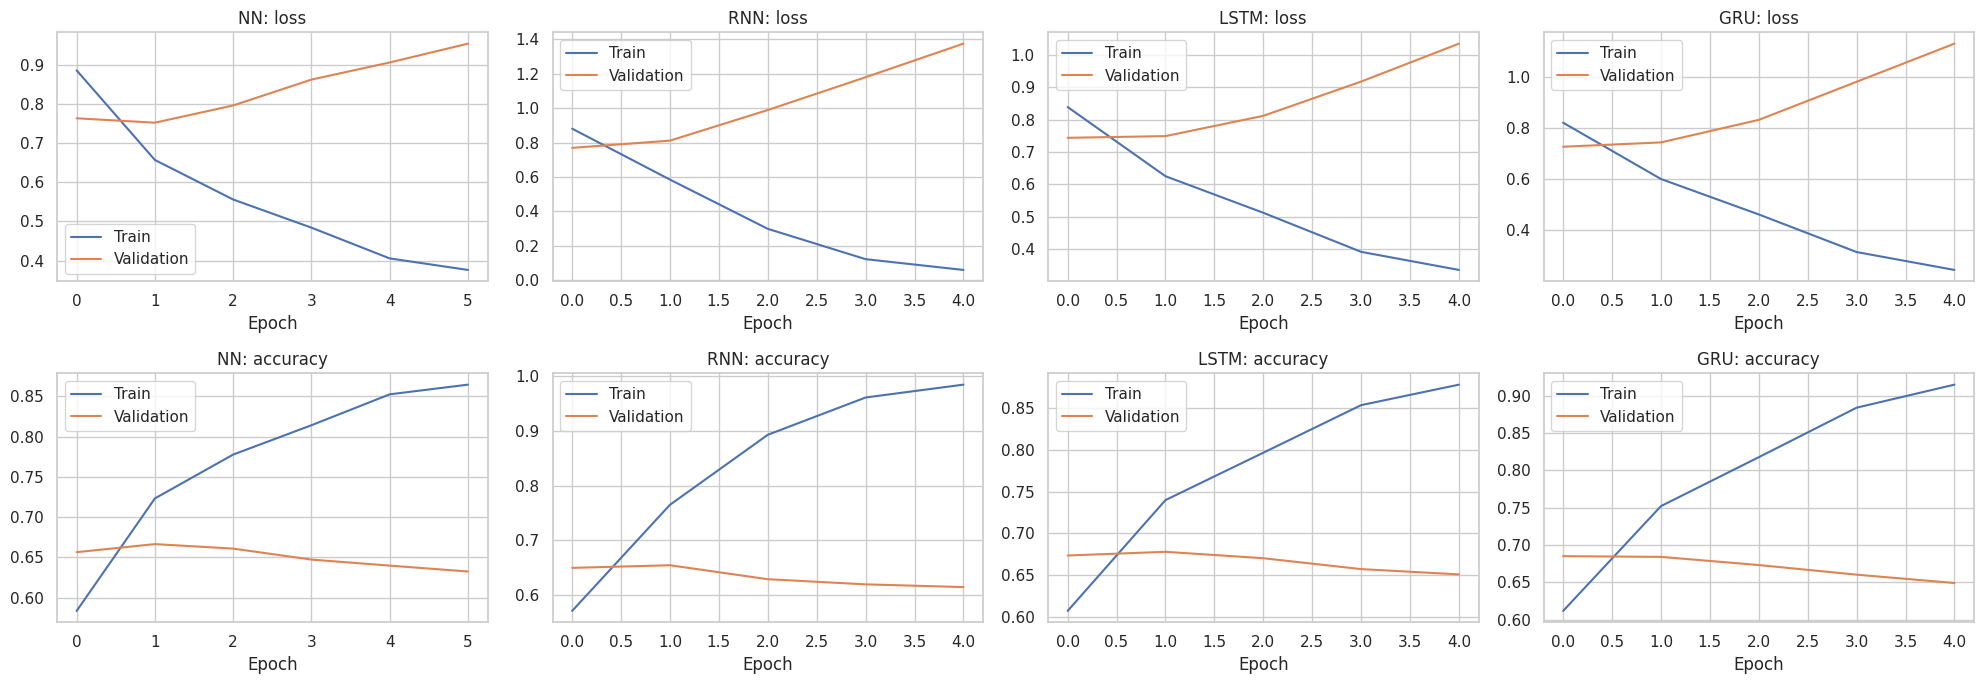

In [29]:
fig, axes = plt.subplots(2, 4, figsize=(20, 7))
for j, arch in enumerate(ARCHS):
    h = histories[arch].history
    axes[0, j].plot(h["loss"], label="Train"); axes[0, j].plot(h["val_loss"], label="Validation")
    axes[0, j].set_title(f"{arch}: loss"); axes[0, j].set_xlabel("Epoch")
    axes[1, j].plot(h["accuracy"], label="Train"); axes[1, j].plot(h["val_accuracy"], label="Validation")
    axes[1, j].set_title(f"{arch}: accuracy"); axes[1, j].set_xlabel("Epoch")
    axes[0, j].legend(); axes[1, j].legend()
plt.tight_layout(); plt.savefig("learning_curves.png", dpi=200); plt.show()

## 15. Inference on new sentences (best model)

In [30]:
def predict_sentiment(texts, model=None):
    model = model or final_models[best_arch]
    seq = vectorizer(np.array([normalize_text(t) for t in texts])).numpy()
    probs = model.predict(seq, verbose=0)
    return pd.DataFrame({
        "text": texts,
        "predicted_sentiment": [LABELS[i] for i in probs.argmax(axis=1)],
        "confidence": probs.max(axis=1).round(4),
        **{f"p_{n.lower()}": probs[:, i].round(3) for i, n in enumerate(LABELS)},
    })

display(predict_sentiment([
    "I absolutely love this product. It is wonderful!",
    "The meeting is scheduled for 3 pm tomorrow.",
    "This is terrible and I am very disappointed.",
    "I ate an ice cream and it was so yummy",
    "Not good at all, I would not recommend it.",
]))

,text,predicted_sentiment,confidence,p_negative,p_neutral,p_positive
0,I absolutely love this product. It is wonderful!,Positive,0.9836,0.002,0.014,0.984
1,The meeting is scheduled for 3 pm tomorrow.,Neutral,0.5514,0.331,0.551,0.117
2,This is terrible and I am very disappointed.,Negative,0.9906,0.991,0.009,0.001
3,I ate an ice cream and it was so yummy,Positive,0.7316,0.080,0.188,0.732
4,"Not good at all, I would not recommend it.",Neutral,0.4198,0.327,0.420,0.253


## 16. Save models and experiment artefacts

In [31]:
OUT = "sentiment_results"
os.makedirs(OUT, exist_ok=True)

for arch, model in final_models.items():
    model.save(os.path.join(OUT, f"{arch.lower()}_model.keras"))

tuning_df.to_csv(os.path.join(OUT, "hyperparameter_trials.csv"), index=False)
best_val_df.to_csv(os.path.join(OUT, "best_validation_configs.csv"), index=False)
comparison.to_csv(os.path.join(OUT, "test_comparison.csv"))
per_class_df.to_csv(os.path.join(OUT, "per_class_metrics.csv"), index=False)
for img in ["model_comparison_chart.png", "confusion_matrices.png", "learning_curves.png"]:
    if os.path.exists(img): shutil.copy(img, OUT)

vocab_list = vectorizer.get_vocabulary()
with open(os.path.join(OUT, "vocabulary.json"), "w") as f: json.dump(vocab_list, f)

def _py(v):
    return v.item() if hasattr(v, "item") else v

summary = {
    "dataset": "Sp1786/multiclass-sentiment-analysis-dataset",
    "best_model": str(best_arch),
    "test_accuracy": float(winner["test_accuracy"]),
    "test_macro_f1": float(winner["test_macro_f1"]),
    "best_hyperparameters": {k: _py(winner[k]) for k in HP_NAMES},
    "max_len": MAX_LEN, "vocab_size": ACTUAL_VOCAB,
    "trials_per_architecture": MAX_TRIALS,
}
with open(os.path.join(OUT, "summary.json"), "w") as f: json.dump(summary, f, indent=2)

zip_path = shutil.make_archive(OUT, "zip", OUT)
print("Saved result archive:", zip_path)
print(json.dumps(summary, indent=2))

# In Google Colab, uncomment to download everything:
# from google.colab import files
# files.download(zip_path)

Saved result archive: /content/sentiment_results.zip
{
  "dataset": "Sp1786/multiclass-sentiment-analysis-dataset",
  "best_model": "GRU",
  "test_accuracy": 0.688568683957733,
  "test_macro_f1": 0.6918870023245178,
  "best_hyperparameters": {
    "embed_dim": 64,
    "units": 128,
    "dropout": 0.2,
    "learning_rate": 0.001,
    "batch_size": 64
  },
  "max_len": 80,
  "vocab_size": 20000,
  "trials_per_architecture": 5
}


## 17. Conclusion

1. Loaded the multiclass sentiment dataset (Negative / Neutral / Positive) with its predefined train, validation and test splits, then cleaned it and checked the class balance.
2. Applied light text normalization, fitted a vectorizer on the training split only, and used class weights to compensate for class imbalance.
3. Built four comparable models: **NN**, **Bidirectional RNN**, **Bidirectional LSTM** and **Bidirectional GRU**.
4. Tuned embedding size, hidden units, dropout, learning rate and batch size **automatically** with Keras Tuner random search over predefined ranges (`MAX_TRIALS` trials per model, early stopping on validation loss).
5. Retrained each model's best configuration and evaluated it once on the test set using accuracy, macro-precision, macro-recall and macro-F1.
6. Selected the best model and parameter configuration, printed below.

**Caveats**
* Results come from a single run and a single seed; models whose scores differ by well under 1 percentage point should be treated as *comparable*, not definitively ranked.
* Random search samples only `MAX_TRIALS` of the possible combinations; a larger budget (or Bayesian / Hyperband tuning) may find slightly better settings.
* Hyperparameters were chosen on the validation split; the test split was used only for the final comparison.

In [32]:
print("FINAL RESULT")
print("=" * 60)
print(f"Best model     : {best_arch}")
print(f"Test accuracy  : {winner['test_accuracy']:.4f} | Test macro-F1: {winner['test_macro_f1']:.4f}")
print("Best parameters:", {p: _py(winner[p]) for p in HP_NAMES})
print("\nRanking by test macro-F1:")
for rank, row in comparison.iterrows():
    print(f"  {rank}. {row['architecture']:<5} accuracy={row['test_accuracy']:.4f}  "
          f"macro-F1={row['test_macro_f1']:.4f}  params={int(row['parameters']):,}")

FINAL RESULT
Best model     : GRU
Test accuracy  : 0.6886 | Test macro-F1: 0.6919
Best parameters: {'embed_dim': 64, 'units': 128, 'dropout': 0.2, 'learning_rate': 0.001, 'batch_size': 64}

Ranking by test macro-F1:
  1. GRU   accuracy=0.6886  macro-F1=0.6919  params=1,429,763
  2. LSTM  accuracy=0.6740  macro-F1=0.6780  params=2,823,939
  3. NN    accuracy=0.6745  macro-F1=0.6777  params=2,576,899
  4. RNN   accuracy=0.6586  macro-F1=0.6633  params=2,585,091
